In [3]:
import os
import sys
import importlib

cwd = os.getcwd()
project_root = cwd

if os.path.basename(cwd) == "notebooks":
    project_root = os.path.abspath("..")
elif not os.path.exists(os.path.join(cwd, "src")):
    for candidate in [os.path.abspath(".."), os.path.abspath(".")]:
        if os.path.exists(os.path.join(candidate, "src")):
            project_root = candidate
            break

if project_root not in sys.path:
    sys.path.insert(0, project_root)

import src.avaliacao as avaliacao
importlib.reload(avaliacao)

<module 'src.avaliacao' from 'c:\\Users\\Pichau\\Documents\\limezashi\\TCC_SAIS\\src\\avaliacao.py'>

In [4]:
from src.preparacao_dados import preparar_dados

X_train, X_test, y_train, y_test = preparar_dados(
    "../data/dataset.csv"
)

In [5]:
from src.modelos import criar_modelos

modelos = criar_modelos()

In [6]:
from src.avaliacao import treinar_modelos

modelos_treinados = treinar_modelos(
    modelos,
    X_train,
    y_train
)

In [7]:
import src.avaliacao as avaliacao

resultados_validacao = avaliacao.validar_modelos(
    modelos,
    X_train,
    y_train
)

In [8]:
resultados_teste = avaliacao.avaliar_modelos(
    modelos_treinados,
    X_test,
    y_test
)

c:\Users\Pichau\Documents\limezashi\TCC_SAIS\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Pichau\Documents\limezashi\TCC_SAIS\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Pichau\Documents\limezashi\TCC_SAIS\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

In [9]:
for nome, resultado in resultados_validacao.items():

    print("\n==============================")
    print(nome)
    print("==============================")

    print(
        f"ROC-AUC: "
        f"{resultado['media_auc']:.4f} "
        f"+/- "
        f"{resultado['desvio_auc']:.4f}"
    )

    print(
        f"Brier: "
        f"{resultado['media_brier']:.4f} "
        f"+/- "
        f"{resultado['desvio_brier']:.4f}"
    )


Regressão Logística
ROC-AUC: 0.6466 +/- 0.0278
Brier: 0.0939 +/- 0.0015

Random Forest
ROC-AUC: 0.5865 +/- 0.0241
Brier: 0.0982 +/- 0.0016

XGBoost
ROC-AUC: 0.5860 +/- 0.0235
Brier: 0.1050 +/- 0.0035

SVM
ROC-AUC: 0.5290 +/- 0.0287
Brier: 0.0962 +/- 0.0002


In [10]:
for nome in resultados_validacao:

    cv = resultados_validacao[nome]
    teste = resultados_teste[nome]

    print(f"\n===== {nome} =====")
    print(f"AUC CV:     {cv['media_auc']:.4f} ± {cv['desvio_auc']:.4f}")
    print(f"Brier CV:   {cv['media_brier']:.4f} ± {cv['desvio_brier']:.4f}")
    print(f"AUC Teste:  {teste['auc']:.4f}")
    print(f"Brier Teste:{teste['brier']:.4f}")


===== Regressão Logística =====
AUC CV:     0.6466 ± 0.0278
Brier CV:   0.0939 ± 0.0015
AUC Teste:  0.6727
Brier Teste:0.0919

===== Random Forest =====
AUC CV:     0.5865 ± 0.0241
Brier CV:   0.0982 ± 0.0016
AUC Teste:  0.6274
Brier Teste:0.0954

===== XGBoost =====
AUC CV:     0.5860 ± 0.0235
Brier CV:   0.1050 ± 0.0035
AUC Teste:  0.6002
Brier Teste:0.1040

===== SVM =====
AUC CV:     0.5290 ± 0.0287
Brier CV:   0.0962 ± 0.0002
AUC Teste:  0.5608
Brier Teste:0.0959


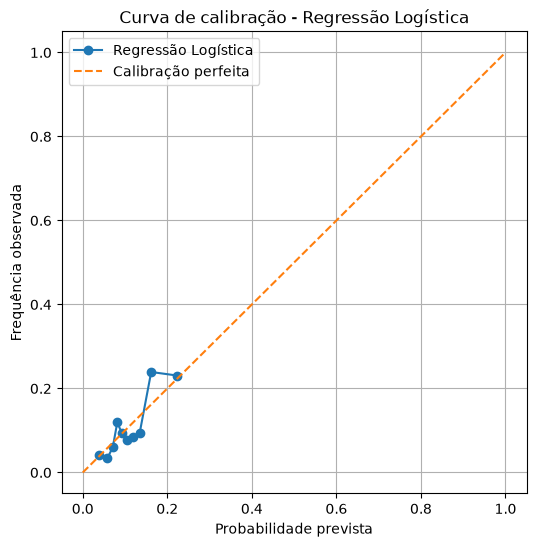

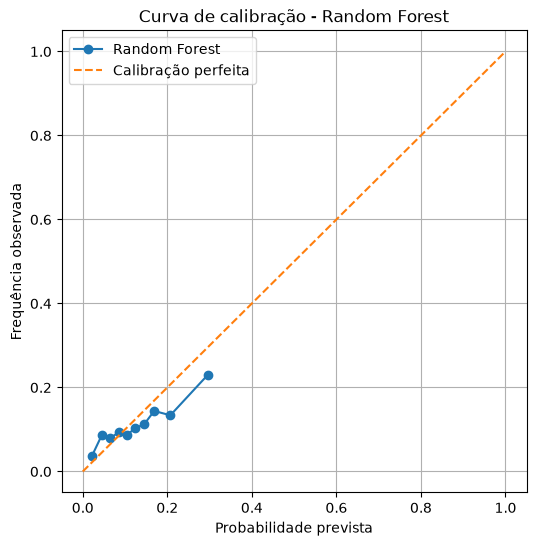

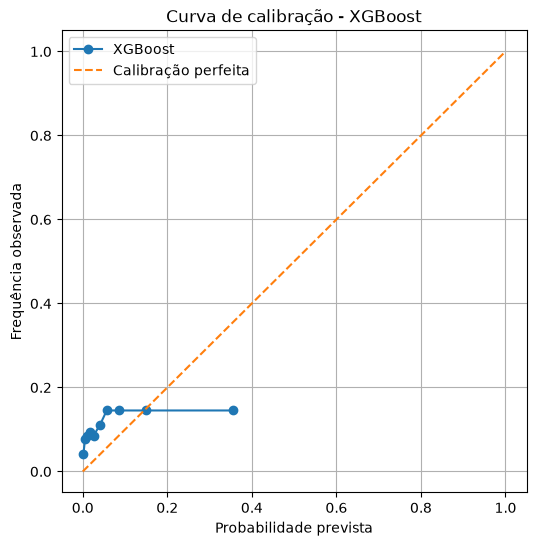

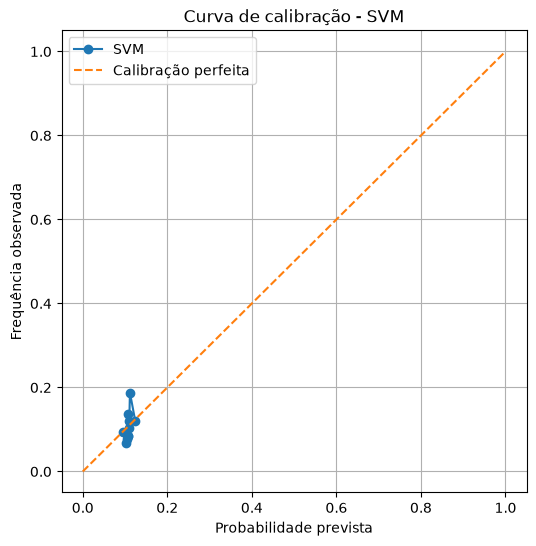

In [11]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

for nome, resultado in resultados_teste.items():

    y_prob = resultado["probabilidades"]

    prob_true, prob_pred = calibration_curve(
        y_test,
        y_prob,
        n_bins=10,
        strategy="quantile"
    )

    plt.figure(figsize=(6, 6))

    plt.plot(
        prob_pred,
        prob_true,
        marker="o",
        label=nome
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Calibração perfeita"
    )

    plt.xlabel("Probabilidade prevista")
    plt.ylabel("Frequência observada")
    plt.title(f"Curva de calibração - {nome}")
    plt.legend()
    plt.grid(True)

    plt.show()

In [12]:
from sklearn.metrics import roc_auc_score, brier_score_loss

probabilidades = {}

for nome, resultado in resultados_teste.items():
    probabilidades[nome] = resultado["probabilidades"]


combinacoes = {
    "RL + RF": ["Regressão Logística", "Random Forest"],
    "RL + XGB": ["Regressão Logística", "XGBoost"],
    "RL + SVM": ["Regressão Logística", "SVM"],
    "RF + XGB": ["Random Forest", "XGBoost"],
    "RF + SVM": ["Random Forest", "SVM"],
    "XGB + SVM": ["XGBoost", "SVM"]
}


resultados_ensemble = {}

for nome, modelos_ensemble in combinacoes.items():

    prob1 = probabilidades[modelos_ensemble[0]]
    prob2 = probabilidades[modelos_ensemble[1]]

    prob_final = (prob1 + prob2) / 2

    auc = roc_auc_score(
        y_test,
        prob_final
    )

    brier = brier_score_loss(
        y_test,
        prob_final
    )

    resultados_ensemble[nome] = {
        "probabilidades": prob_final,
        "auc": auc,
        "brier": brier
    }


for nome, resultado in resultados_ensemble.items():

    print(f"{nome}")
    print(f"  ROC-AUC: {resultado['auc']:.4f}")
    print(f"  Brier:   {resultado['brier']:.4f}")
    print()

RL + RF
  ROC-AUC: 0.6627
  Brier:   0.0925

RL + XGB
  ROC-AUC: 0.6525
  Brier:   0.0947

RL + SVM
  ROC-AUC: 0.6706
  Brier:   0.0932

RF + XGB
  ROC-AUC: 0.6245
  Brier:   0.0966

RF + SVM
  ROC-AUC: 0.6278
  Brier:   0.0941

XGB + SVM
  ROC-AUC: 0.6000
  Brier:   0.0967



In [13]:
import numpy as np

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, brier_score_loss

In [14]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

probabilidades_oof = {}

for nome, modelo in modelos.items():

    probabilidades = np.zeros(len(X_train))

    for indice_treino, indice_validacao in cv.split(X_train, y_train):

        modelo_cv = clone(modelo)

        X_fold_treino = X_train.iloc[indice_treino]
        X_fold_validacao = X_train.iloc[indice_validacao]

        y_fold_treino = y_train.iloc[indice_treino]

        modelo_cv.fit(
            X_fold_treino,
            y_fold_treino
        )

        probabilidades[indice_validacao] = (
            modelo_cv.predict_proba(X_fold_validacao)[:, 1]
        )

    probabilidades_oof[nome] = probabilidades

    print(
        f"{nome}: "
        f"AUC OOF = "
        f"{roc_auc_score(y_train, probabilidades):.4f} | "
        f"Brier OOF = "
        f"{brier_score_loss(y_train, probabilidades):.4f}"
    )

Regressão Logística: AUC OOF = 0.6451 | Brier OOF = 0.0939
Random Forest: AUC OOF = 0.5856 | Brier OOF = 0.0982
XGBoost: AUC OOF = 0.5852 | Brier OOF = 0.1050
SVM: AUC OOF = 0.5214 | Brier OOF = 0.0962


In [15]:
def testar_pesos(prob1, prob2, y, nome_modelo_1, nome_modelo_2):

    resultados = []

    pesos = np.arange(0, 1.01, 0.05)

    for peso in pesos:

        peso_2 = 1 - peso

        prob_final = (
            peso * prob1 +
            peso_2 * prob2
        )

        auc = roc_auc_score(
            y,
            prob_final
        )

        brier = brier_score_loss(
            y,
            prob_final
        )

        resultados.append({
            "peso_1": round(peso, 2),
            "peso_2": round(peso_2, 2),
            "auc": auc,
            "brier": brier
        })

    return resultados

In [16]:
resultados_rl_rf = testar_pesos(
    probabilidades_oof["Regressão Logística"],
    probabilidades_oof["Random Forest"],
    y_train,
    "Regressão Logística",
    "Random Forest"
)

In [17]:
melhor_auc_rl_rf = max(
    resultados_rl_rf,
    key=lambda x: x["auc"]
)

melhor_brier_rl_rf = min(
    resultados_rl_rf,
    key=lambda x: x["brier"]
)

print("RL + RF")
print()
print("Melhor AUC:")
print(melhor_auc_rl_rf)

print()
print("Melhor Brier:")
print(melhor_brier_rl_rf)

RL + RF

Melhor AUC:
{'peso_1': np.float64(1.0), 'peso_2': np.float64(0.0), 'auc': 0.6450640756825144, 'brier': 0.09386941559246155}

Melhor Brier:
{'peso_1': np.float64(1.0), 'peso_2': np.float64(0.0), 'auc': 0.6450640756825144, 'brier': 0.09386941559246155}


In [18]:
resultados_rl_svm = testar_pesos(
    probabilidades_oof["Regressão Logística"],
    probabilidades_oof["SVM"],
    y_train,
    "Regressão Logística",
    "SVM"
)

In [19]:
melhor_auc_rl_svm = max(
    resultados_rl_svm,
    key=lambda x: x["auc"]
)

melhor_brier_rl_svm = min(
    resultados_rl_svm,
    key=lambda x: x["brier"]
)

print("RL + SVM")
print()
print("Melhor AUC:")
print(melhor_auc_rl_svm)

print()
print("Melhor Brier:")
print(melhor_brier_rl_svm)

RL + SVM

Melhor AUC:
{'peso_1': np.float64(0.65), 'peso_2': np.float64(0.35), 'auc': 0.6454554716060263, 'brier': 0.09405609080247351}

Melhor Brier:
{'peso_1': np.float64(0.9), 'peso_2': np.float64(0.1), 'auc': 0.6451635831206953, 'brier': 0.0938517998987359}


In [20]:
import pandas as pd

tabela_pesos = pd.DataFrame(
    resultados_rl_rf
)

tabela_pesos

,peso_1,peso_2,auc,brier
0,0.00,1.00,0.585636,0.098189
1,0.05,0.95,0.590286,0.097766
2,0.10,0.90,0.591917,0.097365
3,0.15,0.85,0.594874,0.096986
4,0.20,0.80,0.598097,0.096628
5,0.25,0.75,0.601435,0.096292
6,0.30,0.70,0.605000,0.095978
7,0.35,0.65,0.608487,0.095686
8,0.40,0.60,0.612075,0.095415
9,0.45,0.55,0.615700,0.095167


In [21]:
import numpy as np

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, brier_score_loss

In [22]:
def gerar_oof_modelos(modelos_base, X, y, n_splits=5):

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    probabilidades_oof = {}

    for nome, modelo in modelos_base.items():

        probabilidades = np.zeros(len(X))

        for indice_treino, indice_validacao in cv.split(X, y):

            modelo_cv = clone(modelo)

            X_fold_treino = X.iloc[indice_treino]
            X_fold_validacao = X.iloc[indice_validacao]

            y_fold_treino = y.iloc[indice_treino]

            modelo_cv.fit(
                X_fold_treino,
                y_fold_treino
            )

            probabilidades[indice_validacao] = (
                modelo_cv.predict_proba(
                    X_fold_validacao
                )[:, 1]
            )

        probabilidades_oof[nome] = probabilidades

    return probabilidades_oof

In [23]:
modelos_rl_rf = {
    "Regressão Logística": modelos["Regressão Logística"],
    "Random Forest": modelos["Random Forest"]
}

prob_oof_rl_rf = gerar_oof_modelos(
    modelos_rl_rf,
    X_train,
    y_train
)

In [24]:
X_meta_rl_rf = np.column_stack([
    prob_oof_rl_rf["Regressão Logística"],
    prob_oof_rl_rf["Random Forest"]
])

In [25]:
meta_rl_rf = LogisticRegression(
    max_iter=1000,
    random_state=42
)

meta_rl_rf.fit(
    X_meta_rl_rf,
    y_train
)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [26]:
prob_meta_rl_rf = meta_rl_rf.predict_proba(
    X_meta_rl_rf
)[:, 1]

auc_meta_rl_rf = roc_auc_score(
    y_train,
    prob_meta_rl_rf
)

brier_meta_rl_rf = brier_score_loss(
    y_train,
    prob_meta_rl_rf
)

print("Stacking RL + RF")
print(f"AUC OOF:   {auc_meta_rl_rf:.4f}")
print(f"Brier OOF: {brier_meta_rl_rf:.4f}")

Stacking RL + RF
AUC OOF:   0.6376
Brier OOF: 0.0943


In [27]:
modelos_rl_svm = {
    "Regressão Logística": modelos["Regressão Logística"],
    "SVM": modelos["SVM"]
}

prob_oof_rl_svm = gerar_oof_modelos(
    modelos_rl_svm,
    X_train,
    y_train
)

In [28]:
X_meta_rl_svm = np.column_stack([
    prob_oof_rl_svm["Regressão Logística"],
    prob_oof_rl_svm["SVM"]
])

In [29]:
meta_rl_svm = LogisticRegression(
    max_iter=1000,
    random_state=42
)

meta_rl_svm.fit(
    X_meta_rl_svm,
    y_train
)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [30]:
prob_meta_rl_svm = meta_rl_svm.predict_proba(
    X_meta_rl_svm
)[:, 1]

auc_meta_rl_svm = roc_auc_score(
    y_train,
    prob_meta_rl_svm
)

brier_meta_rl_svm = brier_score_loss(
    y_train,
    prob_meta_rl_svm
)

print("Stacking RL + SVM")
print(f"AUC OOF:   {auc_meta_rl_svm:.4f}")
print(f"Brier OOF: {brier_meta_rl_svm:.4f}")

Stacking RL + SVM
AUC OOF:   0.6451
Brier OOF: 0.0943


In [31]:
rl_rf_treinados = {}

for nome in ["Regressão Logística", "Random Forest"]:

    modelo = clone(modelos[nome])

    modelo.fit(
        X_train,
        y_train
    )

    rl_rf_treinados[nome] = modelo

In [32]:
prob_test_rl_rf = np.column_stack([
    rl_rf_treinados["Regressão Logística"].predict_proba(X_test)[:, 1],
    rl_rf_treinados["Random Forest"].predict_proba(X_test)[:, 1]
])

In [33]:
prob_final_rl_rf = meta_rl_rf.predict_proba(
    prob_test_rl_rf
)[:, 1]

In [34]:
auc_rl_rf = roc_auc_score(
    y_test,
    prob_final_rl_rf
)

brier_rl_rf = brier_score_loss(
    y_test,
    prob_final_rl_rf
)

print("Stacking RL + RF")
print(f"ROC-AUC: {auc_rl_rf:.4f}")
print(f"Brier:   {brier_rl_rf:.4f}")

Stacking RL + RF
ROC-AUC: 0.6747
Brier:   0.0929


In [35]:
rl_svm_treinados = {}

for nome in ["Regressão Logística", "SVM"]:

    modelo = clone(modelos[nome])

    modelo.fit(
        X_train,
        y_train
    )

    rl_svm_treinados[nome] = modelo

In [36]:
prob_test_rl_svm = np.column_stack([
    rl_svm_treinados["Regressão Logística"].predict_proba(X_test)[:, 1],
    rl_svm_treinados["SVM"].predict_proba(X_test)[:, 1]
])

In [37]:
prob_final_rl_svm = meta_rl_svm.predict_proba(
    prob_test_rl_svm
)[:, 1]

In [38]:
auc_rl_svm = roc_auc_score(
    y_test,
    prob_final_rl_svm
)

brier_rl_svm = brier_score_loss(
    y_test,
    prob_final_rl_svm
)

print("Stacking RL + SVM")
print(f"ROC-AUC: {auc_rl_svm:.4f}")
print(f"Brier:   {brier_rl_svm:.4f}")

Stacking RL + SVM
ROC-AUC: 0.6727
Brier:   0.0931


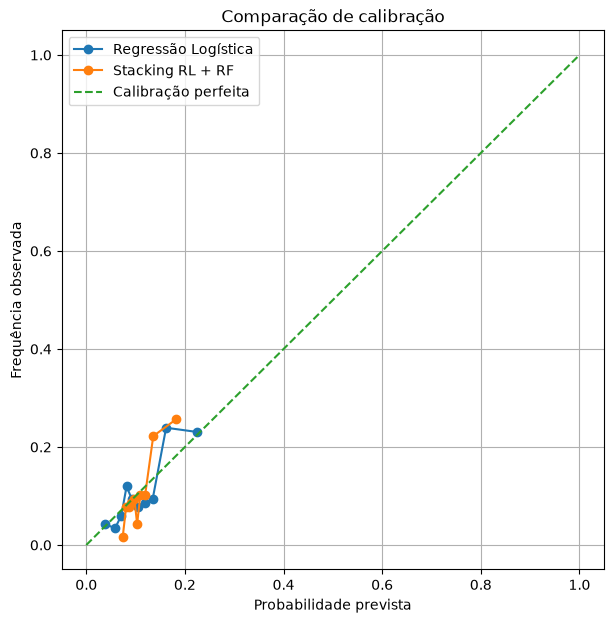

In [39]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

prob_true_rl, prob_pred_rl = calibration_curve(
    y_test,
    resultados_teste["Regressão Logística"]["probabilidades"],
    n_bins=10,
    strategy="quantile"
)

prob_true_stack, prob_pred_stack = calibration_curve(
    y_test,
    prob_final_rl_rf,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 7))

plt.plot(
    prob_pred_rl,
    prob_true_rl,
    marker="o",
    label="Regressão Logística"
)

plt.plot(
    prob_pred_stack,
    prob_true_stack,
    marker="o",
    label="Stacking RL + RF"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Calibração perfeita"
)

plt.xlabel("Probabilidade prevista")
plt.ylabel("Frequência observada")
plt.title("Comparação de calibração")
plt.legend()
plt.grid(True)

plt.show()

In [40]:
import pandas as pd

resultados_finais = pd.DataFrame([
    {
        "Modelo": "Regressão Logística",
        "AUC CV": 0.6466,
        "Brier CV": 0.0939,
        "AUC Teste": 0.6727,
        "Brier Teste": 0.0919
    },
    {
        "Modelo": "Random Forest",
        "AUC CV": 0.5865,
        "Brier CV": 0.0982,
        "AUC Teste": 0.6274,
        "Brier Teste": 0.0954
    },
    {
        "Modelo": "XGBoost",
        "AUC CV": 0.5860,
        "Brier CV": 0.1050,
        "AUC Teste": 0.6002,
        "Brier Teste": 0.1040
    },
    {
        "Modelo": "SVM",
        "AUC CV": 0.5290,
        "Brier CV": 0.0962,
        "AUC Teste": 0.5608,
        "Brier Teste": 0.0959
    },
    {
        "Modelo": "Stacking RL + RF",
        "AUC CV": 0.6376,
        "Brier CV": 0.0943,
        "AUC Teste": 0.6747,
        "Brier Teste": 0.0929
    },
    {
        "Modelo": "Stacking RL + SVM",
        "AUC CV": 0.6451,
        "Brier CV": 0.0943,
        "AUC Teste": 0.6727,
        "Brier Teste": 0.0931
    }
])

resultados_finais

,Modelo,AUC CV,Brier CV,AUC Teste,Brier Teste
0,Regressão Logística,0.6466,0.0939,0.6727,0.0919
1,Random Forest,0.5865,0.0982,0.6274,0.0954
2,XGBoost,0.5860,0.1050,0.6002,0.1040
3,SVM,0.5290,0.0962,0.5608,0.0959
4,Stacking RL + RF,0.6376,0.0943,0.6747,0.0929
5,Stacking RL + SVM,0.6451,0.0943,0.6727,0.0931
